In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/train.csv")

# Display first five records
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate Records:
0


# 02 - Exploratory Data Analysis (EDA)

## Experiment 1 - Survival Distribution

In [5]:
# Count survival categories

survival_counts = df["Survived"].value_counts()

print(survival_counts)

Survived
0    549
1    342
Name: count, dtype: int64


In [6]:
# Calculate survival percentage

survival_percentage = (
    df["Survived"].value_counts(normalize=True) * 100
)

print(survival_percentage)

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


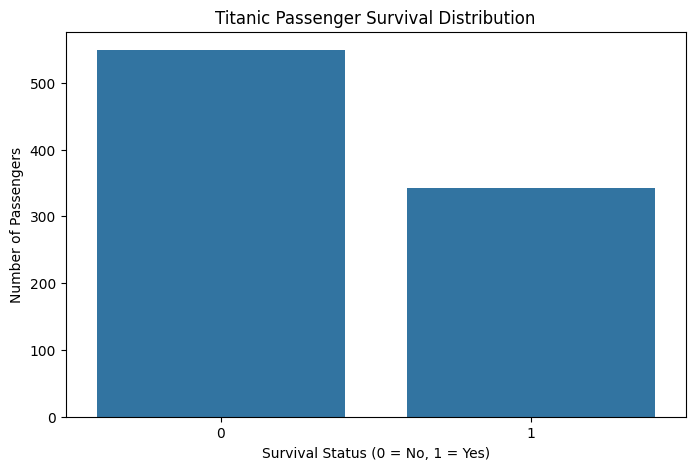

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Survived")

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [8]:
total = len(df)

survived = (df["Survived"] == 1).sum()
not_survived = (df["Survived"] == 0).sum()

print("Total Passengers:", total)
print("Survived:", survived)
print("Not Survived:", not_survived)

print("Survival Rate:", round(survived / total * 100, 2), "%")

Total Passengers: 891
Survived: 342
Not Survived: 549
Survival Rate: 38.38 %


In [9]:
from sklearn.metrics import accuracy_score
import numpy as np

# Actual survival values
y_actual = df["Survived"]

# Predict 0 for every passenger
y_pred = np.zeros(len(df), dtype=int)

# Calculate accuracy
accuracy = accuracy_score(y_actual, y_pred)

print("Baseline Accuracy:", accuracy * 100, "%")

Baseline Accuracy: 61.61616161616161 %


## Experiment 2 - Gender vs Survival

In [10]:
gender_counts = df.groupby(
    ["Sex", "Survived"]
).size().unstack(fill_value=0)

print(gender_counts)

Survived    0    1
Sex               
female     81  233
male      468  109


In [11]:
gender_survival = (
    df.groupby("Sex")["Survived"].mean() * 100
)

print("Gender-wise Survival Rate:")
print(gender_survival)

Gender-wise Survival Rate:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


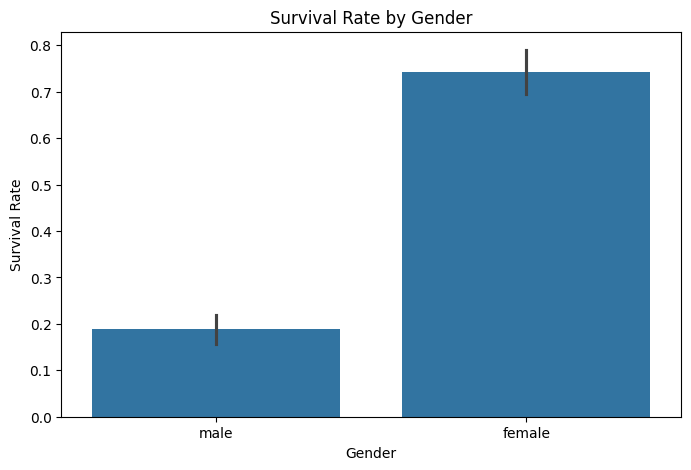

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived"
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

In [13]:
# Survival count by passenger class

class_survival = df.groupby(
    ["Pclass", "Survived"]
).size().unstack(fill_value=0)

print(class_survival)



Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


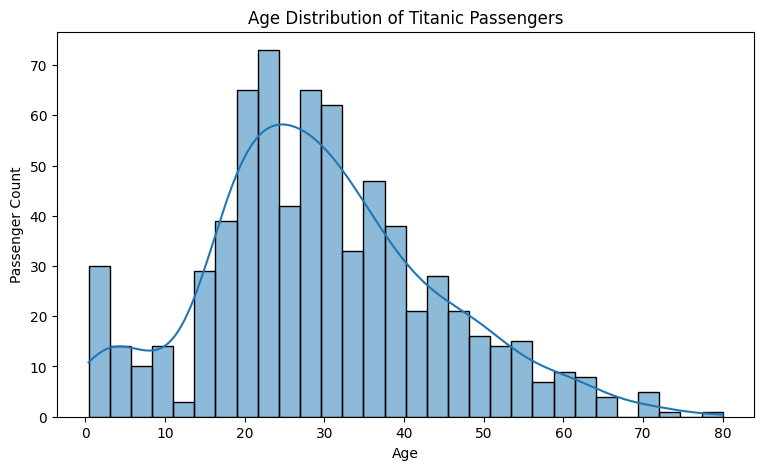

In [14]:
#Age distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Passenger Count")

plt.show()

In [15]:
print(df["Age"].describe())

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64


Experiment 5 — Age vs Survival

In [16]:
age_survival = df.groupby("Survived")["Age"].mean()

print(age_survival)

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64


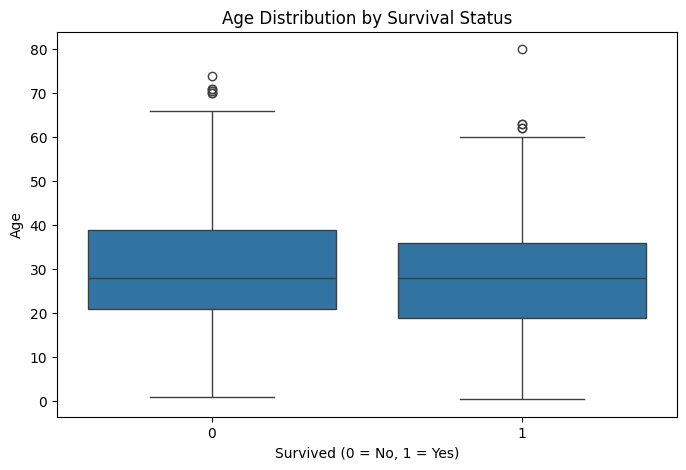

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Age"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

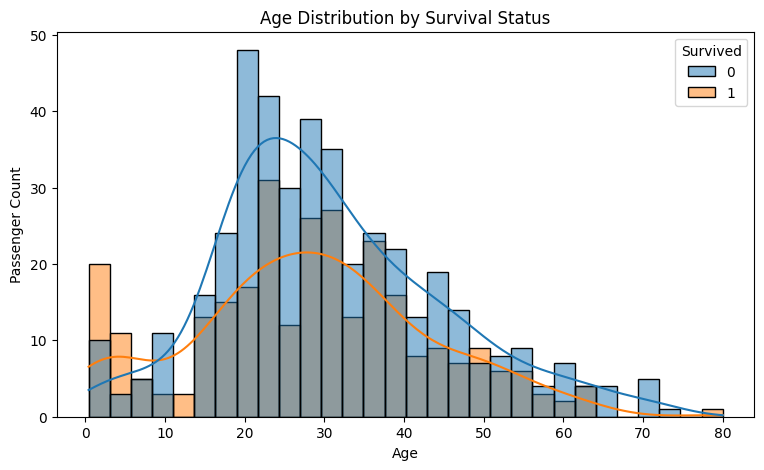

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Passenger Count")

plt.show()

Experiment 6 — Fare Distribution Analysis

In [19]:
print(df["Fare"].describe())

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


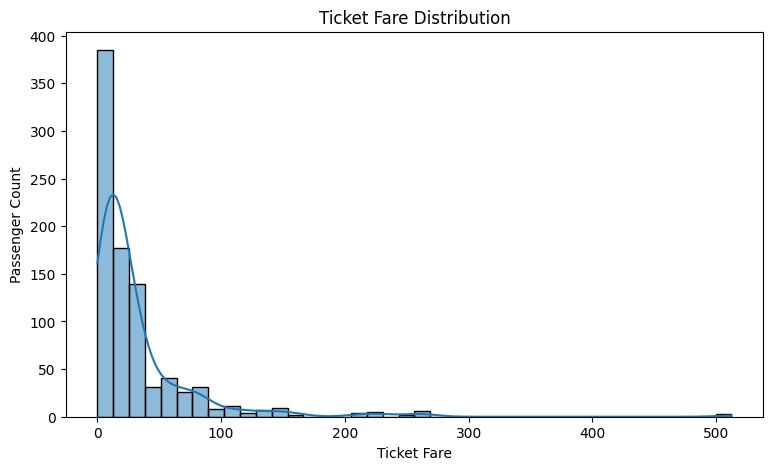

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Fare",
    bins=40,
    kde=True
)

plt.title("Ticket Fare Distribution")
plt.xlabel("Ticket Fare")
plt.ylabel("Passenger Count")

plt.show()

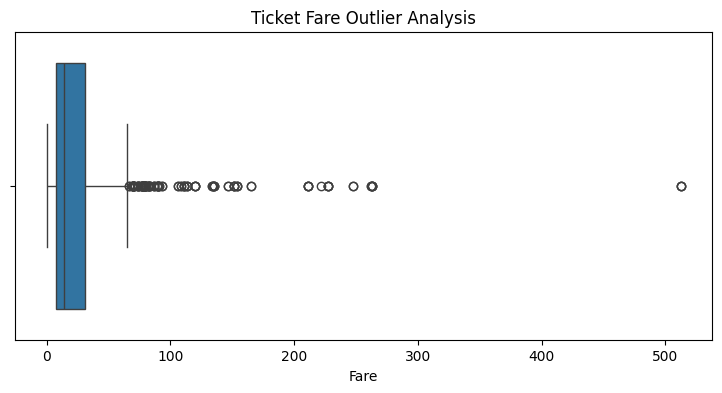

In [21]:
plt.figure(figsize=(9, 4))

sns.boxplot(data=df, x="Fare")

plt.title("Ticket Fare Outlier Analysis")
plt.xlabel("Fare")

plt.show()

In [22]:
print("Fare Skewness:", df["Fare"].skew())


Fare Skewness: 4.787316519674893


In [23]:
fare_survival = df.groupby("Survived")["Fare"].mean()

print(fare_survival)

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


In [24]:
fare_median = df.groupby("Survived")["Fare"].median()

print(fare_median)

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64


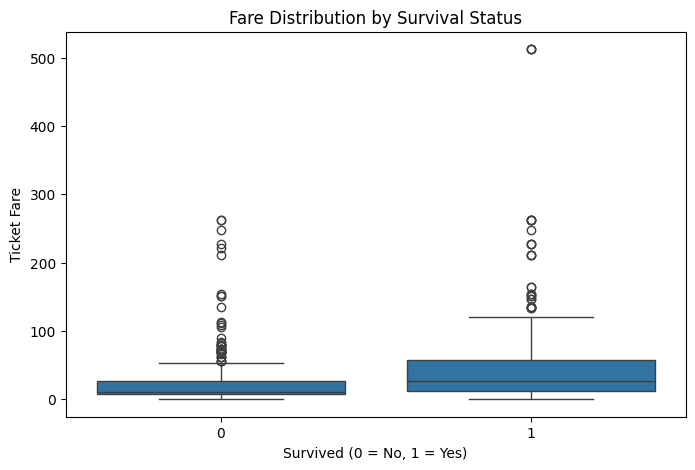

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Survived",
    y="Fare"
)

plt.title("Fare Distribution by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")

plt.show()

In [26]:
df["FareGroup"] = pd.qcut(
    df["Fare"],
    q=4,
    duplicates="drop"
)

fare_group_survival = (
    df.groupby("FareGroup", observed=True)["Survived"].mean() * 100
)

print(fare_group_survival)

FareGroup
(-0.001, 7.91]     19.730942
(7.91, 14.454]     30.357143
(14.454, 31.0]     45.495495
(31.0, 512.329]    58.108108
Name: Survived, dtype: float64


Experiment 8 — Family Size Analysis

In [27]:
print("Siblings and Spouses:")
print(df["SibSp"].value_counts().sort_index())

print("\nParents and Children:")
print(df["Parch"].value_counts().sort_index())

Siblings and Spouses:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

Parents and Children:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64


In [28]:

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

print(df["FamilySize"].value_counts().sort_index())

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64


In [29]:
family_survival = (
    df.groupby("FamilySize")["Survived"].mean() * 100
)

print(family_survival)

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


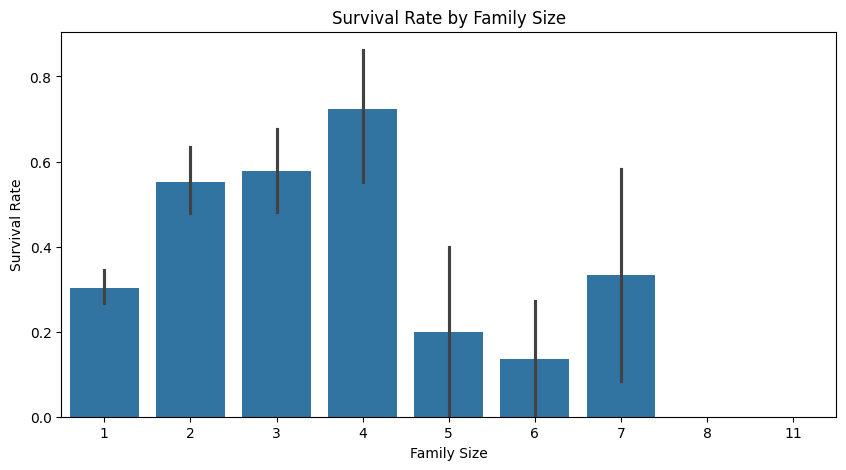

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="FamilySize",
    y="Survived"
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

In [31]:
df["TravelGroup"] = np.where(
    df["FamilySize"] == 1,
    "Alone",
    "With Family"
)

travel_survival = (
    df.groupby("TravelGroup")["Survived"].mean() * 100
)

print(travel_survival)

TravelGroup
Alone          30.353818
With Family    50.564972
Name: Survived, dtype: float64


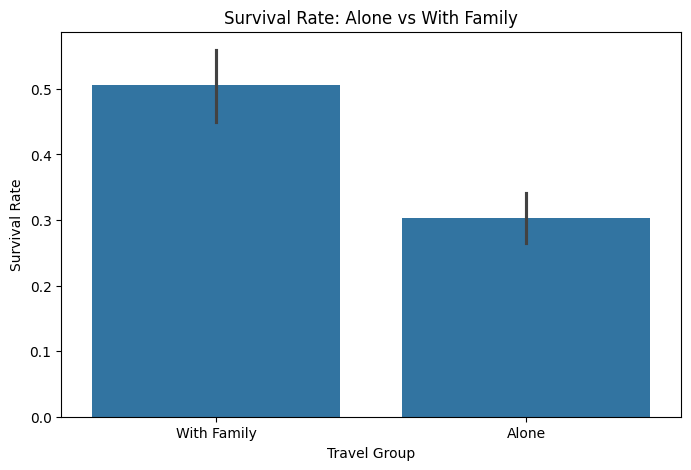

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="TravelGroup",
    y="Survived"
)

plt.title("Survival Rate: Alone vs With Family")
plt.xlabel("Travel Group")
plt.ylabel("Survival Rate")

plt.show()

## Experiment 9

In [33]:
print(df["Embarked"].value_counts())

Embarked
S           644
C           167
Q            77
Ctraeeas      1
Name: count, dtype: int64


In [34]:
print(df["Embarked"].isnull().sum())

2


In [35]:
embarked_survival = df.groupby(
    ["Embarked", "Survived"]
).size().unstack(fill_value=0)

print(embarked_survival)

Survived    0    1
Embarked          
C          74   93
Ctraeeas    1    0
Q          47   30
S         427  217


In [36]:
embarked_percentage = (
    df.groupby("Embarked")["Survived"].mean() * 100
)

print("Survival Rate by Embarkation Port:")
print(embarked_percentage)

Survival Rate by Embarkation Port:
Embarked
C           55.688623
Ctraeeas     0.000000
Q           38.961039
S           33.695652
Name: Survived, dtype: float64


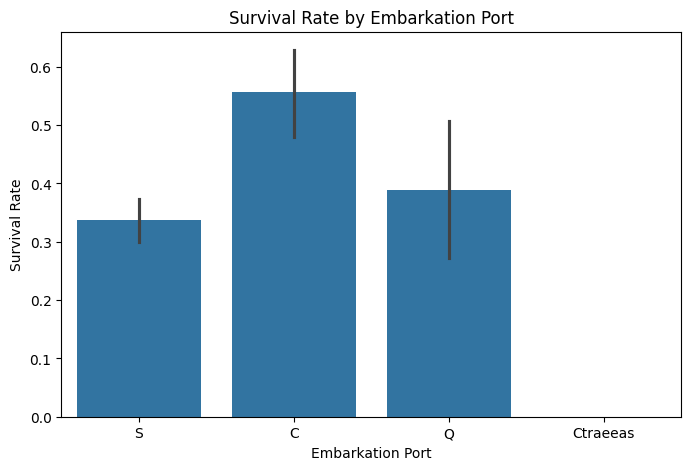

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Embarked",
    y="Survived"
)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")

plt.show()

Experiment 10 — Correlation Analysis

In [38]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Calculate correlation
correlation = numeric_df.corr()

print(correlation)

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005007 -0.035144  0.036847 -0.057527 -0.001652   
Survived       -0.005007  1.000000 -0.338481 -0.077221 -0.035322  0.081629   
Pclass         -0.035144 -0.338481  1.000000 -0.369226  0.083081  0.018443   
Age             0.036847 -0.077221 -0.369226  1.000000 -0.308247 -0.189119   
SibSp          -0.057527 -0.035322  0.083081 -0.308247  1.000000  0.414838   
Parch          -0.001652  0.081629  0.018443 -0.189119  0.414838  1.000000   
Fare            0.012658  0.257307 -0.549500  0.096067  0.159651  0.216225   
FamilySize     -0.040143  0.016639  0.065997 -0.301914  0.890712  0.783111   

                 Fare  FamilySize  
PassengerId  0.012658   -0.040143  
Survived     0.257307    0.016639  
Pclass      -0.549500    0.065997  
Age          0.096067   -0.301914  
SibSp        0.159651    0.890712  
Parch        0.216225    0.783111  
Fare         1.000000    0.217138  
FamilySiz

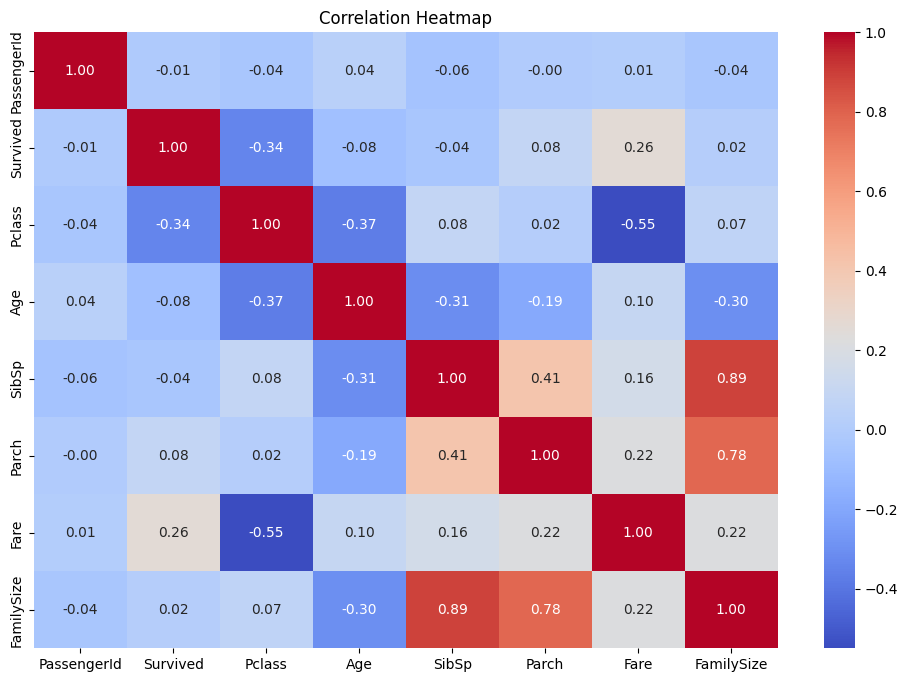

In [39]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## Experiment 11 — Final EDA Experiment

In [40]:
#Missing value summary
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

print(missing_summary)

             Missing_Count  Missing_Percentage
PassengerId              0            0.000000
Survived                 0            0.000000
Pclass                   0            0.000000
Name                     0            0.000000
Sex                      0            0.000000
Age                    177           19.865320
SibSp                    0            0.000000
Parch                    0            0.000000
Ticket                   0            0.000000
Fare                     0            0.000000
Cabin                  687           77.104377
Embarked                 2            0.224467
FareGroup                0            0.000000
FamilySize               0            0.000000
TravelGroup              0            0.000000


In [41]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [42]:
#Numerical outlier investigation using IQR

numerical_columns = [
    "Age", "Fare", "SibSp", "Parch"
]

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(f"\n{col}")
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Potential Outliers:", len(outliers))


Age
Lower Bound: -6.6875
Upper Bound: 64.8125
Potential Outliers: 11

Fare
Lower Bound: -26.724
Upper Bound: 65.6344
Potential Outliers: 116

SibSp
Lower Bound: -1.5
Upper Bound: 2.5
Potential Outliers: 46

Parch
Lower Bound: 0.0
Upper Bound: 0.0
Potential Outliers: 213


In [43]:
#Final dataset dimensions
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
print(df.dtypes)

Dataset Shape: (891, 15)

Column Information:
PassengerId       int64
Survived          int64
Pclass            int64
Name                str
Sex                 str
Age             float64
SibSp             int64
Parch             int64
Ticket              str
Fare            float64
Cabin               str
Embarked            str
FareGroup      category
FamilySize        int64
TravelGroup         str
dtype: object


## Phase 3 - Data Preprocessing

### Step 1: Feature Selection and Target Separation

In [44]:

# Select input features
X = df[
    ["Pclass", "Sex", "Age", "Fare", "Embarked", "FamilySize"]
]

# Select target variable
y = df["Survived"]

# Display dimensions
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Feature Shape: (891, 6)
Target Shape: (891,)

Target Distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [45]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (712, 6)
Testing Features: (179, 6)
Training Target: (712,)
Testing Target: (179,)


In [46]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [47]:

numeric_features = ["Age", "Fare", "FamilySize"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


In [48]:
#Create categorical preprocessing

categorical_features = ["Pclass", "Sex", "Embarked"]

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)


In [49]:
#Combine both preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


In [50]:
#Fit and transform the training data

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Training Data Shape: (712, 12)
Testing Data Shape: (179, 12)


In [51]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_processed, y_train)

print("Model Training Completed!")

Model Training Completed!


In [52]:
print("Model:", model)
print("Training Accuracy:", model.score(X_train_processed, y_train))
print("Testing Accuracy:", model.score(X_test_processed, y_test))

Model: LogisticRegression()
Training Accuracy: 0.8075842696629213
Testing Accuracy: 0.7988826815642458


Confusion Matrix:
[[97 13]
 [23 46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       110
           1       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179



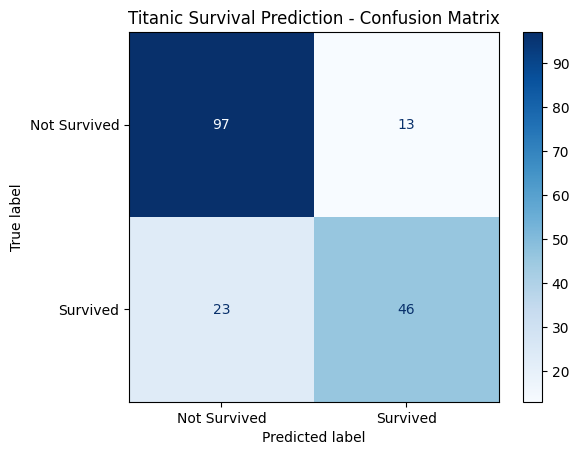

In [53]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using test data
y_pred = model.predict(X_test_processed)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Visualize Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues"
)

plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.show()

ROC-AUC Score: 0.8392621870882739


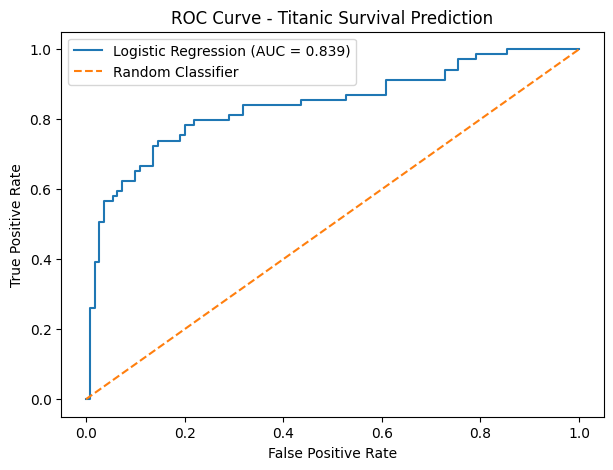

In [54]:
#ROC curve and AUC
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get survival probabilities
y_prob = model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc_score)

# Plot ROC Curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Titanic Survival Prediction")
plt.legend()
plt.show()

## 7. ROC Curve and AUC Evaluation

**Algorithm:** Logistic Regression

**ROC-AUC Score:** 0.8393 (83.93%)

### Observations

1. The ROC curve remains above the random classifier reference line.
2. The model demonstrates good ability to distinguish between survivors and non-survivors.
3. The AUC score indicates useful class-ranking performance across different classification thresholds.
4. The model's AUC score is higher than its classification accuracy because AUC measures ranking performance across thresholds rather than accuracy at one fixed threshold.

### Conclusion

The Logistic Regression model achieved an ROC-AUC score of 0.8393, indicating good discriminatory ability. However, survivor recall remains at 67% at the default classification threshold of 0.5. Further experimentation may help improve the balance between precision and recall.

## Random Forest Classifier

In [55]:
from sklearn.ensemble import RandomForestClassifier

In [56]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [57]:
rf_model.fit(X_train_processed, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [58]:
#Evaluate accuracy
from sklearn.metrics import accuracy_score

# Predictions
rf_train_pred = rf_model.predict(X_train_processed)
rf_test_pred = rf_model.predict(X_test_processed)

# Accuracy
rf_train_accuracy = accuracy_score(y_train, rf_train_pred)
rf_test_accuracy = accuracy_score(y_test, rf_test_pred)

print("Random Forest Training Accuracy:", rf_train_accuracy)
print("Random Forest Testing Accuracy:", rf_test_accuracy)

Random Forest Training Accuracy: 0.9831460674157303
Random Forest Testing Accuracy: 0.8044692737430168


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Random Forest Confusion Matrix:
[[97 13]
 [22 47]]


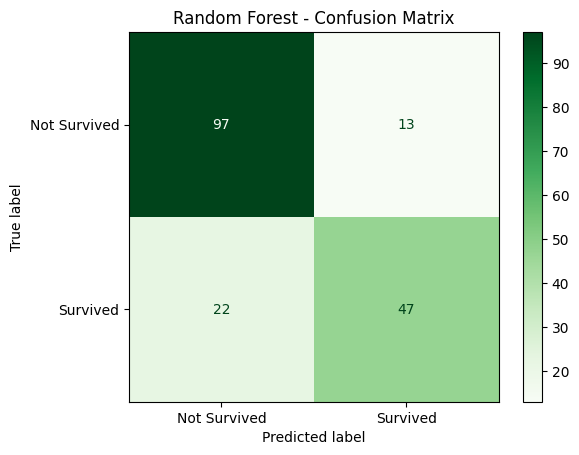

Random Forest ROC-AUC: 0.829973649538867


In [59]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Classification report
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_test_pred))

# Confusion matrix
cm_rf = confusion_matrix(y_test, rf_test_pred)

print("Random Forest Confusion Matrix:")
print(cm_rf)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

# ROC-AUC
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC:", rf_auc)

In [60]:
#Random Forest hyperparameter tuning
rf_tuned = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=42
)

rf_tuned.fit(X_train_processed, y_train)

print("Training Accuracy:", rf_tuned.score(X_train_processed, y_train))
print("Testing Accuracy:", rf_tuned.score(X_test_processed, y_test))

Training Accuracy: 0.8497191011235955
Testing Accuracy: 0.8044692737430168


Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.86       110
           1       0.87      0.58      0.70        69

    accuracy                           0.80       179
   macro avg       0.83      0.76      0.78       179
weighted avg       0.82      0.80      0.79       179

Confusion Matrix:
[[104   6]
 [ 29  40]]


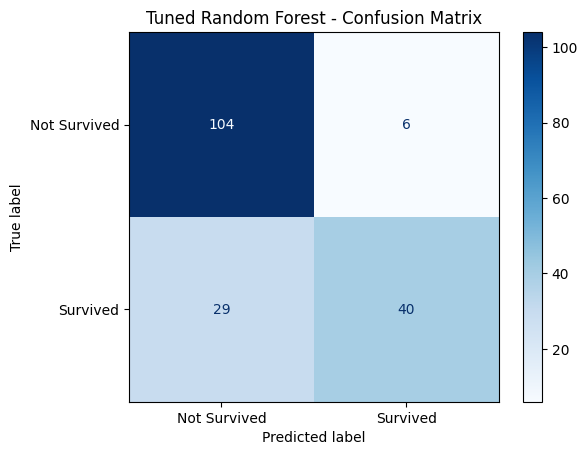

Tuned Random Forest ROC-AUC: 0.8370223978919631


In [61]:
#Evaluate the tuned model
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions
rf_tuned_pred = rf_tuned.predict(X_test_processed)

# Classification report
print("Tuned Random Forest Classification Report:")
print(classification_report(y_test, rf_tuned_pred))

# Confusion matrix
cm_tuned = confusion_matrix(y_test, rf_tuned_pred)

print("Confusion Matrix:")
print(cm_tuned)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_tuned_pred,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

# ROC-AUC
rf_tuned_prob = rf_tuned.predict_proba(X_test_processed)[:, 1]
rf_tuned_auc = roc_auc_score(y_test, rf_tuned_prob)

print("Tuned Random Forest ROC-AUC:", rf_tuned_auc)

                 Model  Training Accuracy  Testing Accuracy  ROC-AUC
0  Logistic Regression             0.8076            0.7989   0.8393
1        Random Forest             0.9831            0.8045   0.8356
2  Tuned Random Forest             0.8483            0.8045   0.8345


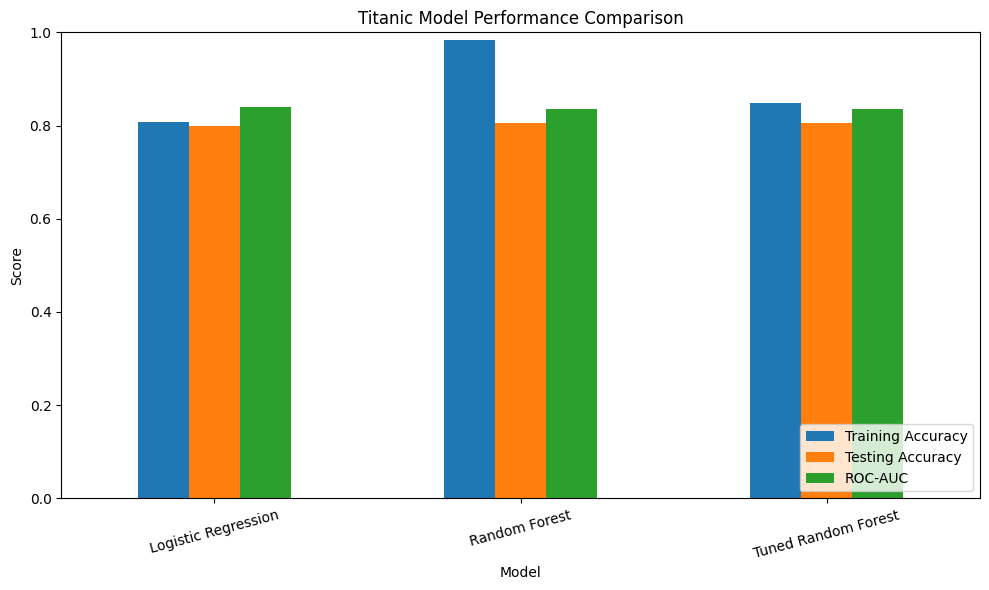

In [62]:
#Compare all models visually

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Training Accuracy": [
        0.8076, 0.9831, 0.8483
    ],
    "Testing Accuracy": [
        0.7989, 0.8045, 0.8045
    ],
    "ROC-AUC": [
        0.8393, 0.8356, 0.8345
    ]
})

print(comparison)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Titanic Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [63]:
#Classification threshold tuning
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Create validation data from the training set
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Fit a fresh preprocessor only on subtraining data
validation_preprocessor = clone(preprocessor)

X_subtrain_processed = validation_preprocessor.fit_transform(X_subtrain)
X_val_processed = validation_preprocessor.transform(X_val)

# Train Logistic Regression
lr_validation = LogisticRegression(max_iter=1000)
lr_validation.fit(X_subtrain_processed, y_subtrain)

# Get survival probabilities
val_prob = lr_validation.predict_proba(X_val_processed)[:, 1]

# Test different thresholds
for threshold in [0.3, 0.4, 0.5, 0.6]:
    val_pred = (val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val, val_pred))
    print("Recall:", recall_score(y_val, val_pred))
    print("F1-score:", f1_score(y_val, val_pred))


Threshold: 0.3
Precision: 0.6666666666666666
Recall: 0.8
F1-score: 0.7272727272727273

Threshold: 0.4
Precision: 0.6842105263157895
Recall: 0.7090909090909091
F1-score: 0.6964285714285714

Threshold: 0.5
Precision: 0.72
Recall: 0.6545454545454545
F1-score: 0.6857142857142857

Threshold: 0.6
Precision: 0.7727272727272727
Recall: 0.6181818181818182
F1-score: 0.6868686868686869



Threshold: 0.5
Accuracy: 0.7988826815642458
              precision    recall  f1-score   support

           0       0.81      0.88      0.84       110
           1       0.78      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.80      0.80      0.80       179


Threshold: 0.3
Accuracy: 0.770949720670391
              precision    recall  f1-score   support

           0       0.86      0.75      0.80       110
           1       0.67      0.80      0.73        69

    accuracy                           0.77       179
   macro avg       0.76      0.78      0.77       179
weighted avg       0.78      0.77      0.77       179



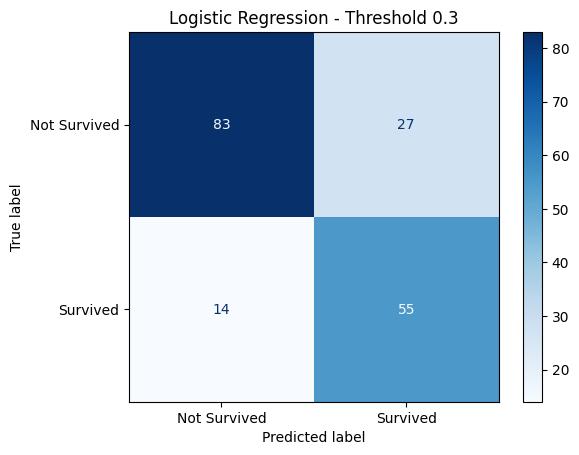

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train final Logistic Regression on the full training data
final_lr = LogisticRegression(max_iter=1000)
final_lr.fit(X_train_processed, y_train)

# Get predicted probabilities on test data
test_prob = final_lr.predict_proba(X_test_processed)[:, 1]

# Default threshold
pred_05 = (test_prob >= 0.5).astype(int)

# Selected threshold
pred_03 = (test_prob >= 0.3).astype(int)

# Compare both thresholds
for threshold, predictions in [(0.5, pred_05), (0.3, pred_03)]:
    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(y_test, predictions))

# Confusion matrix for threshold 0.3
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_03,
    display_labels=["Not Survived", "Survived"],
    cmap="Blues"
)

plt.title("Logistic Regression - Threshold 0.3")
plt.show()

In [65]:
# Extract feature names from preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))
print("\nFeature Names:")

for feature in feature_names:
    print(feature)

Total Features: 12

Feature Names:
num__Age
num__Fare
num__FamilySize
cat__Pclass_1
cat__Pclass_2
cat__Pclass_3
cat__Sex_female
cat__Sex_male
cat__Embarked_C
cat__Embarked_Ctraeeas
cat__Embarked_Q
cat__Embarked_S


In [66]:
import pandas as pd

# Extract coefficients
coefficients = final_lr.coef_[0]

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort coefficients
feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(feature_importance)

                   Feature  Coefficient
6          cat__Sex_female     1.327708
3            cat__Pclass_1     0.998978
10         cat__Embarked_Q     0.345650
1                num__Fare     0.139356
8          cat__Embarked_C     0.124607
4            cat__Pclass_2     0.113093
9   cat__Embarked_Ctraeeas    -0.129113
2          num__FamilySize    -0.269629
11         cat__Embarked_S    -0.308508
0                 num__Age    -0.480483
5            cat__Pclass_3    -1.079433
7            cat__Sex_male    -1.295071


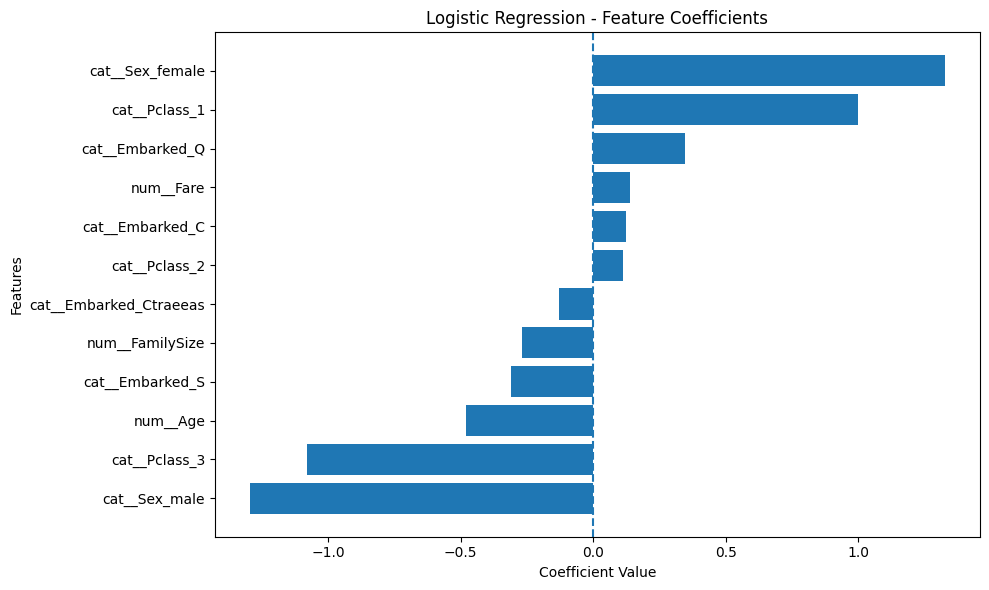

In [67]:
import matplotlib.pyplot as plt

# Sort for visualization
plot_data = feature_importance.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Logistic Regression - Feature Coefficients")

plt.tight_layout()
plt.show()

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create complete ML pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Stratified 5-Fold Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate accuracy
cv_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross Validation Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.7972028  0.7972028  0.80985915 0.78169014 0.82394366]
Mean CV Accuracy: 0.8019797104304146
Standard Deviation: 0.014154894890856475


In [69]:
from sklearn.model_selection import cross_validate

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_metrics
)

for metric in scoring_metrics:
    scores = cv_results[f"test_{metric}"]

    print(f"\n{metric.upper()}")
    print("Fold Scores:", scores)
    print("Mean:", scores.mean())
    print("Standard Deviation:", scores.std())


ACCURACY
Fold Scores: [0.7972028  0.7972028  0.80985915 0.78169014 0.82394366]
Mean: 0.8019797104304146
Standard Deviation: 0.014154894890856475

PRECISION
Fold Scores: [0.74074074 0.79545455 0.79166667 0.7254902  0.78431373]
Mean: 0.767533174886116
Standard Deviation: 0.028736951240433444

RECALL
Fold Scores: [0.72727273 0.63636364 0.69090909 0.68518519 0.74074074]
Mean: 0.6960942760942761
Standard Deviation: 0.03654872461745835

F1
Fold Scores: [0.73394495 0.70707071 0.73786408 0.7047619  0.76190476]
Mean: 0.7291092811071435
Standard Deviation: 0.021232367920829442

ROC_AUC
Fold Scores: [0.85919421 0.8232438  0.87680251 0.83406987 0.87626263]
Mean: 0.8539146031896816
Standard Deviation: 0.021843426022502294


In [70]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Complete ML pipeline
final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train using the complete training dataset
final_pipeline.fit(X_train, y_train)

print("Final Logistic Regression Pipeline Trained!")

Final Logistic Regression Pipeline Trained!


In [71]:
import joblib

In [72]:
!pip install joblib

In [73]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save pipeline and threshold
model_artifact = {
    "pipeline": final_pipeline,
    "threshold": 0.3
}

joblib.dump(
    model_artifact,
    "../models/logistic_regression_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [74]:
loaded_artifact = joblib.load(
    "../models/logistic_regression_pipeline.pkl"
)

loaded_pipeline = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

print("Model loaded successfully!")
print("Selected Threshold:", loaded_threshold)

Model loaded successfully!
Selected Threshold: 0.3


In [75]:
import pandas as pd

new_passenger = pd.DataFrame({
    "Pclass": [1],
    "Sex": ["female"],
    "Age": [25],
    "Fare": [80],
    "Embarked": ["C"],
    "FamilySize": [2]
})

print(new_passenger)

   Pclass     Sex  Age  Fare Embarked  FamilySize
0       1  female   25    80        C           2


In [76]:
survival_probability = loaded_pipeline.predict_proba(
    new_passenger
)[:, 1]

print("Survival Probability:", survival_probability[0])

Survival Probability: 0.9506199125291583


In [77]:
prediction = (
    survival_probability >= loaded_threshold
).astype(int)

if prediction[0] == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Did Not Survive")

Prediction: Survived
